In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Works when run from the project root or from the notebooks folder
DATA_PATH = Path('../data/sales_data.csv') if Path('../data/sales_data.csv').exists() else Path('data/sales_data.csv')
df = pd.read_csv(DATA_PATH)
df.head()

,month,region,product,units_sold,unit_price,unit_cost,revenue,profit
0,2025-01,North,Laptop,12,720,500,8640,2640
1,2025-01,South,Phone,24,420,270,10080,3600
2,2025-01,East,Tablet,18,260,170,4680,1620
3,2025-02,North,Phone,20,420,270,8400,3000
4,2025-02,South,Laptop,8,720,500,5760,1760


In [2]:
print('Rows, columns:', df.shape)
print('Missing values by column:\n', df.isna().sum())
df['month'] = pd.to_datetime(df['month'])
df['revenue'] = df['units_sold'] * df['unit_price']
df['profit'] = df['units_sold'] * (df['unit_price'] - df['unit_cost'])
df.describe(include='all')

Rows, columns: (18, 8)
Missing values by column:
 month         0
region        0
product       0
units_sold    0
unit_price    0
unit_cost     0
revenue       0
profit        0
dtype: int64


,month,region,product,units_sold,unit_price,unit_cost,revenue,profit
count,18,18,18,18.000000,18.000000,18.000000,18.000000,18.000000
unique,NaN,3,3,NaN,NaN,NaN,NaN,NaN
top,NaN,North,Phone,NaN,NaN,NaN,NaN,NaN
freq,NaN,6,7,NaN,NaN,NaN,NaN,NaN
mean,2025-03-17 04:00:00,NaN,NaN,21.055556,475.555556,318.888889,8971.111111,3043.333333
min,2025-01-01 00:00:00,NaN,NaN,8.000000,260.000000,170.000000,4680.000000,1620.000000
25%,2025-02-01 00:00:00,NaN,NaN,13.500000,300.000000,195.000000,6565.000000,2212.500000
50%,2025-03-16 12:00:00,NaN,NaN,23.000000,420.000000,270.000000,8520.000000,2750.000000
75%,2025-05-01 00:00:00,NaN,NaN,26.750000,720.000000,500.000000,11205.000000,3937.500000
max,2025-06-01 00:00:00,NaN,NaN,34.000000,720.000000,500.000000,14280.000000,5100.000000


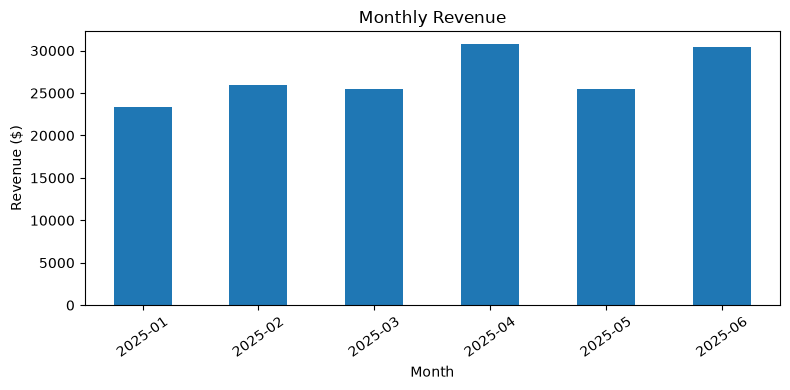

In [3]:
monthly = df.groupby(df['month'].dt.strftime('%Y-%m'), as_index=False)['revenue'].sum()
ax = monthly.plot(x='month', y='revenue', kind='bar', legend=False, figsize=(8,4), title='Monthly Revenue')
ax.set_xlabel('Month'); ax.set_ylabel('Revenue ($)'); plt.xticks(rotation=35); plt.tight_layout(); plt.show()

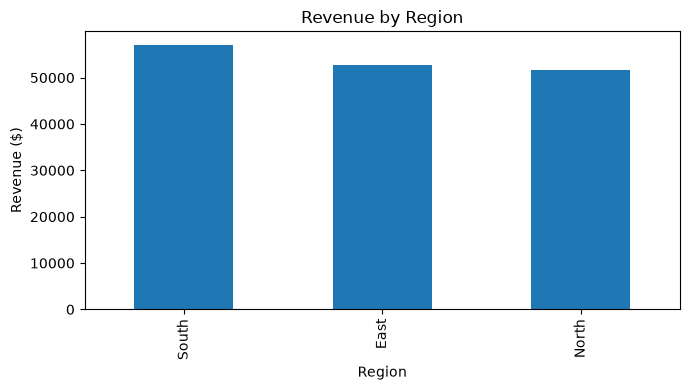

In [4]:
region = df.groupby('region', as_index=False)['revenue'].sum().sort_values('revenue', ascending=False)
ax = region.plot(x='region', y='revenue', kind='bar', legend=False, figsize=(7,4), title='Revenue by Region')
ax.set_xlabel('Region'); ax.set_ylabel('Revenue ($)'); plt.tight_layout(); plt.show()

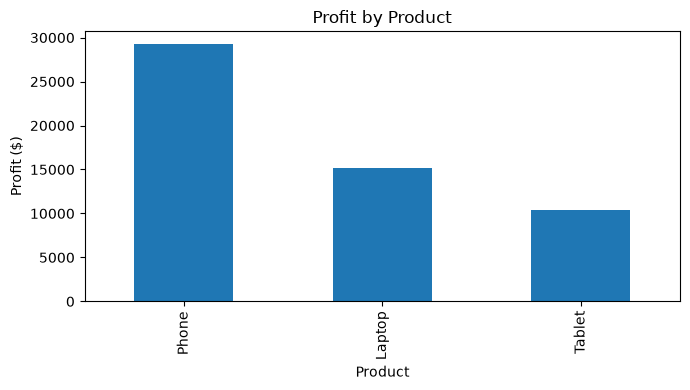

In [5]:
product = df.groupby('product', as_index=False)['profit'].sum().sort_values('profit', ascending=False)
ax = product.plot(x='product', y='profit', kind='bar', legend=False, figsize=(7,4), title='Profit by Product')
ax.set_xlabel('Product'); ax.set_ylabel('Profit ($)'); plt.tight_layout(); plt.show()